# Chapitre 6 - Lissage par noyaux (2) : dimension $p$, vraisemblance locale, densités, mélanges

Ce second notebook couvre les sections 6.3 à 6.8 du livre :
1. la régression locale dans $\mathbb R^p$ et ses limites (fig. 6.8, données *galaxy*) ;
2. les modèles locaux **structurés** : noyaux structurés, modèles additifs, conditionnement
   (fig. 6.9, données *ozone*), modèles à coefficients variables (fig. 6.10-6.11) ;
3. la **vraisemblance locale** : régression logistique locale (fig. 6.12, *SAheart*) ;
4. l'**estimation de densité** par noyau et la classification qui en découle, dont le
   **Bayes naïf** (fig. 6.13-6.15) ;
5. les **fonctions de base radiales** (fig. 6.16) ;
6. les **mélanges gaussiens** et l'algorithme EM (fig. 6.17).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch06_noyaux as nk
set_style()
GREEN, YELLOW, RED = COLORS[2], COLORS[3], COLORS[7]
rng = np.random.RandomState(0)

## 1. Régression locale dans $\mathbb R^p$

Tout se généralise directement. Soit $b(X)$ le vecteur des monômes en $X \in \mathbb R^p$
de degré au plus $d$ ; par exemple pour $p = 2$ :
- $d = 0$ : $b(X) = 1$ ;
- $d = 1$ : $b(X) = (1, X_1, X_2)$ ;
- $d = 2$ : $b(X) = (1, X_1, X_2, X_1^2, X_2^2, X_1X_2)$.

En chaque $x_0 \in \mathbb R^p$ on résout (éq. (6.12) du livre)
$$
\min_{\beta(x_0)} \sum_{i=1}^N K_\lambda(x_0, x_i)\,\big(y_i - b(x_i)^T\beta(x_0)\big)^2,
\qquad \hat f(x_0) = b(x_0)^T\hat\beta(x_0),
$$
avec un noyau **radial** (éq. (6.13)) : $K_\lambda(x_0, x) = D(\|x - x_0\|/\lambda)$,
$\|\cdot\|$ la norme euclidienne.

> **Remarque.** La norme euclidienne dépend des unités de chaque coordonnée : on
> **standardise** en général les prédicteurs (écart-type 1) avant de lisser.

> **Intuition.** Les effets de bord sont bien pires en dimension 2 ou plus, car la
> proportion de points proches du bord est plus grande. La régression **linéaire** locale
> corrige automatiquement le biais de bord au premier ordre, quelle que soit la forme
> (même très irrégulière) du bord : c'est pourquoi on la préfère à Nadaraya-Watson.

### Proportion de points « au bord »

Pour $X$ uniforme sur $[0,1]^p$, la probabilité d'être à distance $< 0{,}05$ du bord est
$1 - \mathbb P(\text{toutes les coordonnées dans } [0{,}05;\,0{,}95]) = 1 - 0{,}9^p$
(indépendance des coordonnées). Elle tend vers 1 : c'est une manifestation du **fléau de
la dimension**.

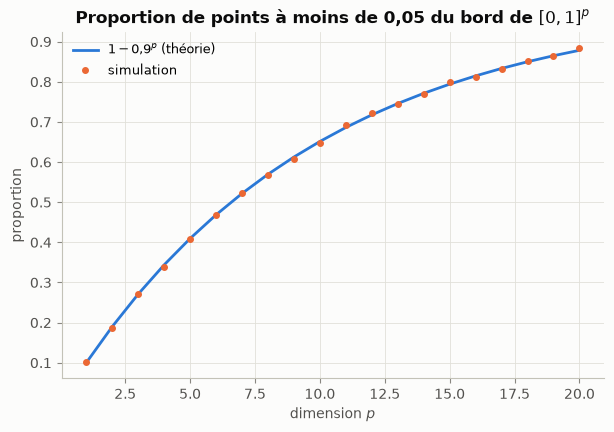

In [2]:
ps = np.arange(1, 21)
emp = [np.mean(np.any((U < 0.05) | (U > 0.95), axis=1))
       for U in (rng.uniform(size=(20000, p)) for p in ps)]
plt.figure(figsize=(7, 4.5))
plt.plot(ps, 1 - 0.9 ** ps, label="$1 - 0{,}9^p$ (théorie)")
plt.plot(ps, emp, "o", ms=4, label="simulation")
plt.title("Proportion de points à moins de 0,05 du bord de $[0,1]^p$")
plt.xlabel("dimension $p$"); plt.ylabel("proportion"); plt.legend(); plt.show()

### Figure 6.8 : les données *galaxy*

La réponse est la vitesse radiale mesurée sur la galaxie NGC 7531 ; les deux prédicteurs
sont des positions (est-ouest, sud-nord) sur la sphère céleste. Les mesures ont été faites
le long de fentes rayonnantes, d'où un plan d'expérience **en étoile** au bord très
irrégulier.

In [3]:
gal = datasets.load_galaxy()
Xg = gal[["east.west", "north.south"]].to_numpy()
yg = gal["velocity"].to_numpy()
print(gal.shape)
gal.head()

(323, 5)


,east.west,north.south,angle,radial.position,velocity
0,8.462789,-38.173172,102.5,39.099998,1769
1,7.964978,-35.927692,102.5,36.799999,1749
2,7.467167,-33.682213,102.5,34.500001,1749
3,6.969356,-31.436731,102.5,32.200000,1758
4,6.471544,-29.191250,102.5,29.899999,1750


On ajuste une régression **linéaire locale** dans $\mathbb R^2$ (tri-cube) avec une fenêtre
des plus proches voisins contenant 15 % des données, comme dans le livre. On n'affiche
l'ajustement qu'à l'intérieur de l'enveloppe convexe des données (au-delà on extrapolerait).

In [4]:
from scipy.spatial import Delaunay

kg = int(round(0.15 * len(yg)))
g1 = np.linspace(Xg[:, 0].min(), Xg[:, 0].max(), 70)
g2 = np.linspace(Xg[:, 1].min(), Xg[:, 1].max(), 70)
G1, G2 = np.meshgrid(g1, g2)
Q = np.column_stack([G1.ravel(), G2.ravel()])
inside = Delaunay(Xg).find_simplex(Q) >= 0
fit = np.full(Q.shape[0], np.nan)
fit[inside] = nk.local_regression(Q[inside], Xg, yg, k=kg, degree=1, kernel="tricube")
print("k = %d voisins ; ajustement calculé en %d points de grille" % (kg, inside.sum()))

k = 48 voisins ; ajustement calculé en 4113 points de grille


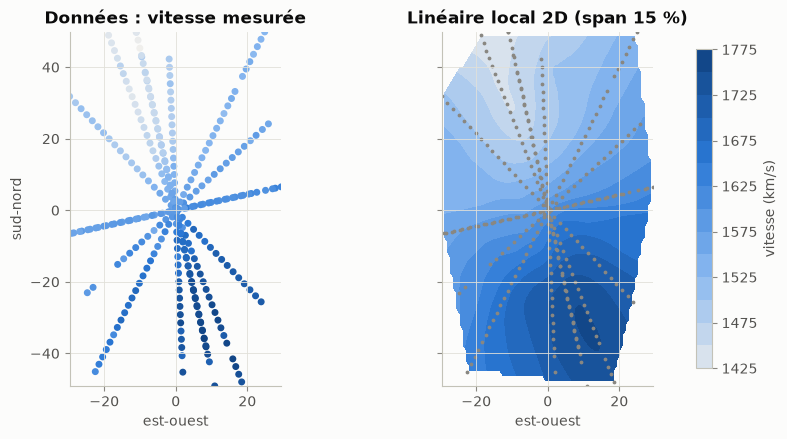

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
vmin, vmax = yg.min(), yg.max()
sc = axes[0].scatter(Xg[:, 0], Xg[:, 1], c=yg, cmap=SEQ, s=16, vmin=vmin, vmax=vmax)
axes[0].set_title("Données : vitesse mesurée")
cf = axes[1].contourf(G1, G2, fit.reshape(G1.shape), levels=15, cmap=SEQ, vmin=vmin, vmax=vmax)
axes[1].scatter(Xg[:, 0], Xg[:, 1], s=3, color=GRAY)
axes[1].set_title("Linéaire local 2D (span 15 %)")
for ax in axes:
    ax.set_xlabel("est-ouest"); ax.set_aspect("equal")
axes[0].set_ylabel("sud-nord")
fig.colorbar(cf, ax=axes, label="vitesse (km/s)", shrink=0.9)
plt.show()

La surface obtenue est lisse et interpole raisonnablement entre les branches de l'étoile,
là où les données se raréfient. On y voit la rotation de la galaxie : vitesses élevées
d'un côté, faibles de l'autre.

> **À retenir.** Au-delà de $p = 2$ ou $3$, la régression locale perd beaucoup d'intérêt :
> on ne peut pas à la fois garder des voisinages **petits** (biais faible) et **peuplés**
> (variance faible) sans une taille d'échantillon qui croît exponentiellement avec $p$.
> On impose alors de la **structure**.

## 2. Modèles locaux structurés

### Noyaux structurés (éq. (6.14))

Au lieu d'un noyau sphérique, on peut pondérer les directions par une matrice
semi-définie positive $\mathbf A$ :
$$
K_{\lambda, A}(x_0, x) = D\!\left(\frac{(x - x_0)^T\mathbf A(x - x_0)}{\lambda}\right).
$$
Avec $\mathbf A$ diagonale on augmente ou diminue l'influence de chaque prédicteur ; un
coefficient nul supprime une variable de la distance. Pour des prédicteurs très corrélés
(signaux, images), on peut construire $\mathbf A$ à partir de leur covariance
(exercice 6.4). Dans le module, `A` définit la distance $\sqrt{(x-x_0)^T\mathbf A(x-x_0)}$.

### Fonctions de régression structurées : décomposition ANOVA (éq. (6.15))

On écrit
$$
f(X_1,\dots,X_p) = \alpha + \sum_j g_j(X_j) + \sum_{k<\ell} g_{k\ell}(X_k, X_\ell) + \cdots
$$
et on supprime les termes d'ordre élevé. Le **modèle additif** ne garde que les effets
principaux $g_j$. On l'ajuste par **backfitting** (chapitre 9) : si tous les termes sauf
$g_k$ sont connus, on estime $g_k$ par régression locale **unidimensionnelle** des résidus
partiels $y - \alpha - \sum_{j\ne k} g_j(X_j)$ sur $X_k$ ; on cycle jusqu'à convergence.

### Les données *ozone*

111 jours de mesures à New York : concentration d'ozone, rayonnement solaire, température
et vitesse du vent. Comme le livre, on modélise la **racine cubique** de l'ozone.

In [6]:
oz = datasets.load_ozone()
yo = np.cbrt(oz["ozone"].to_numpy())
Xo = oz[["radiation", "temperature", "wind"]].to_numpy(float)
names = ["rayonnement", "température", "vent"]
oz.describe().round(1)

,ozone,radiation,temperature,wind
count,111.0,111.0,111.0,111.0
mean,42.1,184.8,77.8,9.9
std,33.3,91.2,9.5,3.6
min,1.0,7.0,57.0,2.3
25%,18.0,113.5,71.0,7.4
50%,31.0,207.0,79.0,9.7
75%,62.0,255.5,84.5,11.5
max,168.0,334.0,97.0,20.7


Backfitting d'un modèle additif avec des lisseurs linéaires locaux (tri-cube, span 50 %).
Chaque fonction est recentrée (moyenne nulle) pour que la constante $\alpha$ soit
identifiable.

In [7]:
n_o = len(yo)
alpha = yo.mean()
gfun = np.zeros((n_o, 3))
k_add = int(0.5 * n_o)
for it in range(30):
    old = gfun.copy()
    for j in range(3):
        partial = yo - alpha - gfun.sum(axis=1) + gfun[:, j]
        gj = nk.local_regression(Xo[:, j], Xo[:, j], partial, k=k_add, degree=1)
        gfun[:, j] = gj - gj.mean()
    if np.max(np.abs(gfun - old)) < 1e-8:
        break
res = yo - alpha - gfun.sum(axis=1)
print("itérations : %d, R^2 du modèle additif = %.3f" % (it + 1, 1 - res.var() / yo.var()))

itérations : 19, R^2 du modèle additif = 0.769


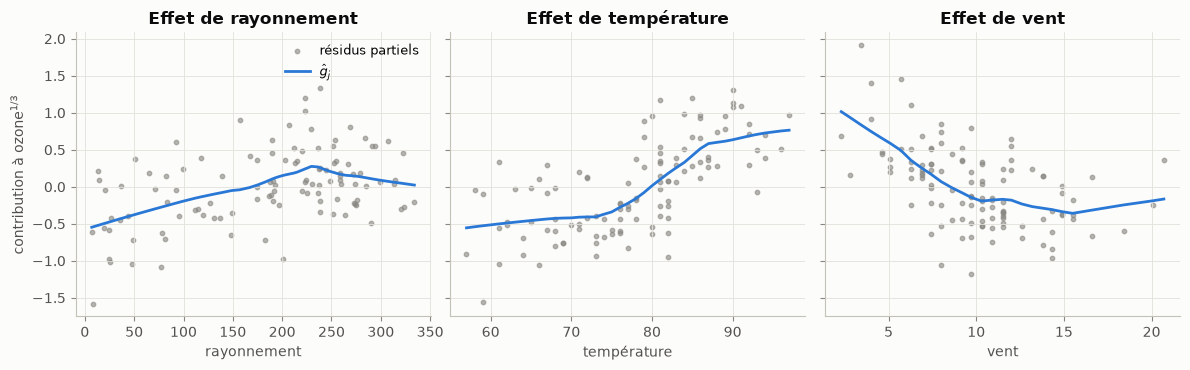

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for j, ax in enumerate(axes):
    o = np.argsort(Xo[:, j])
    ax.scatter(Xo[:, j], gfun[:, j] + res, s=10, color=GRAY, alpha=0.6, label="résidus partiels")
    ax.plot(Xo[o, j], gfun[o, j], color=BLUE, label="$\\hat g_j$")
    ax.set_xlabel(names[j]); ax.set_title("Effet de %s" % names[j])
axes[0].set_ylabel("contribution à ozone$^{1/3}$"); axes[0].legend()
plt.tight_layout(); plt.show()

### Figure 6.9 : graphique conditionnel (« trellis »)

Autre manière de structurer : on regarde l'ozone en fonction du rayonnement,
**conditionnellement** à des intervalles de température et de vent. Dans chaque panneau,
une régression linéaire locale **univariée** est ajustée aux seules données du panneau.
Les intervalles se chevauchent et contiennent chacun environ 40 % des valeurs.

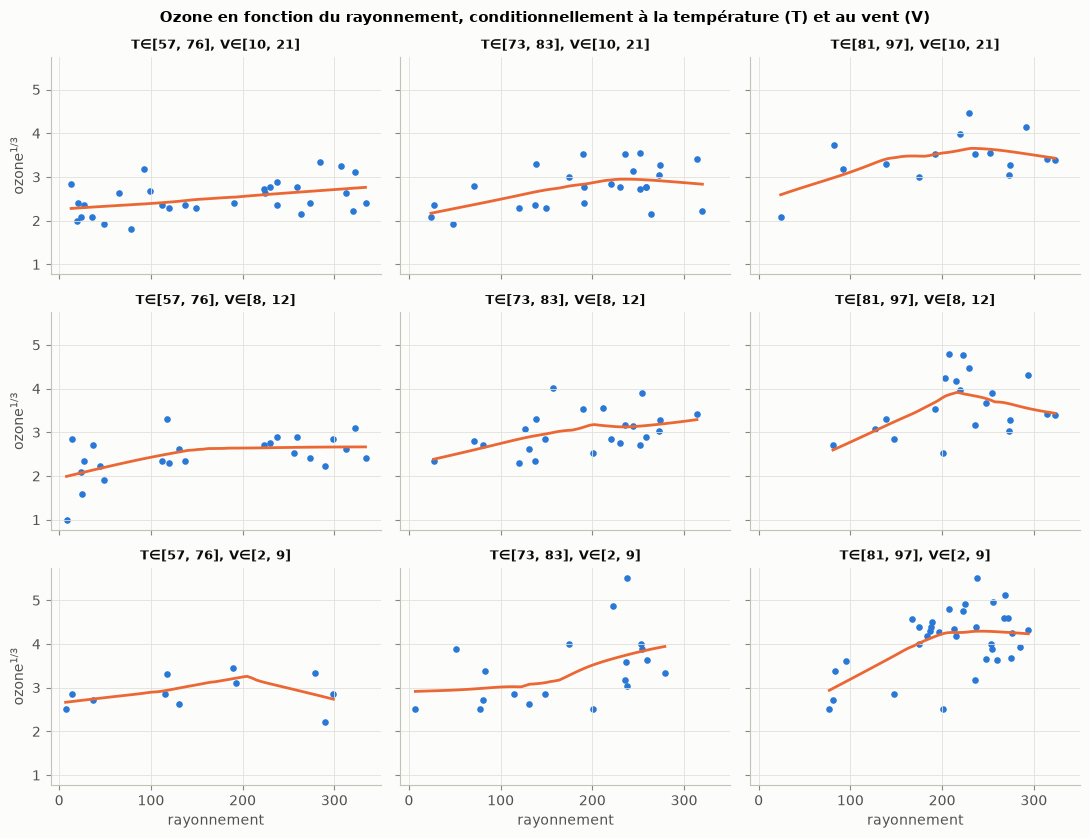

In [9]:
def overlapping_intervals(v, n=3, frac=0.4):
    starts = np.linspace(0, 1 - frac, n)
    return [tuple(np.quantile(v, [s, s + frac])) for s in starts]

t_int = overlapping_intervals(Xo[:, 1])
w_int = overlapping_intervals(Xo[:, 2])
fig, axes = plt.subplots(3, 3, figsize=(11, 8.5), sharex=True, sharey=True)
for a, (wl, wh) in enumerate(w_int[::-1]):
    for b, (tl, th) in enumerate(t_int):
        ax = axes[a, b]
        m = (Xo[:, 1] >= tl) & (Xo[:, 1] <= th) & (Xo[:, 2] >= wl) & (Xo[:, 2] <= wh)
        ax.scatter(Xo[m, 0], yo[m], s=14, color=BLUE)
        if m.sum() >= 5:
            gr = np.linspace(Xo[m, 0].min(), Xo[m, 0].max(), 60)
            ax.plot(gr, nk.local_regression(gr, Xo[m, 0], yo[m], k=max(4, int(0.8 * m.sum())),
                                            degree=1), color=ORANGE)
        ax.set_title("T∈[%d, %d], V∈[%.0f, %.0f]" % (tl, th, wl, wh), fontsize=9)
        if a == 2: ax.set_xlabel("rayonnement")
        if b == 0: ax.set_ylabel("ozone$^{1/3}$")
fig.suptitle("Ozone en fonction du rayonnement, conditionnellement à la température (T) et au vent (V)",
             fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

On lit facilement les interactions : l'effet du rayonnement est fort quand il fait chaud
et que le vent est faible (en bas à droite), presque nul par vent fort et temps frais.